# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0


In [2]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [3]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [4]:
# Desarrollo
# Construye el diagnóstico y escribe el contrato en una celda Markdown.

n_suelo0, n_terr0 = len(suelo), len(territorio)
for nombre, df in [("AGROSAVIA", suelo), ("DIVIPOLA", territorio)]:
    txt = df.apply(lambda s: s.str.strip())
    diag = pd.DataFrame({"dtype": df.dtypes.astype(str), "nulos": df.isna().sum(),
                         "vacios": txt.eq("").sum(), "ND": txt.apply(lambda s: s.str.upper()).eq("ND").sum()})
    print(nombre, df.shape); display(diag)

# Columnas buscadas por nombre (sin tildes ni mayúsculas)
norm = lambda c: c.str.normalize("NFKD").str.replace(r"[\u0300-\u036f]", "", regex=True).str.lower().str.strip()
col = lambda df, patron: df.columns[norm(df.columns).str.contains(patron)][0]
C_FECHA, C_PH = "Fecha de Análisis", "pH agua:suelo"
C_DEP_S, C_MUN_S = col(suelo, r"^departamento$"), col(suelo, r"^municipio$")
C_COD_DEP, C_COD_MUN = col(territorio, "codigo dep"), col(territorio, "codigo mun")
C_NOM_DEP, C_NOM_MUN = col(territorio, r"^(?:nombre )?departamento$"), col(territorio, r"^(?:nombre )?municipio$")
C_LON, C_LAT = col(territorio, "^longitud$"), col(territorio, "^latitud$")
print(C_DEP_S, C_MUN_S, C_COD_DEP, C_COD_MUN, C_NOM_DEP, C_NOM_MUN, C_LON, C_LAT, sep=" | ")

print("Ejemplos fecha:", suelo[C_FECHA].head(5).tolist(), "| pH:", suelo[C_PH].head(5).tolist())
print("Ejemplos nombres:", suelo[[C_DEP_S, C_MUN_S]].head(3).values.tolist(), territorio[[C_NOM_DEP, C_NOM_MUN]].head(3).values.tolist())
print("Ejemplos coordenadas:", territorio[[C_LON, C_LAT]].head(3).values.tolist())

AGROSAVIA (92738, 32)


,dtype,nulos,vacios,ND
Secuencial,object,0,0,0
Fecha de Análisis,object,0,0,0
Departamento,object,0,0,0
Municipio,object,0,2,0
Cultivo,object,0,0,0
Estado,object,0,0,0
Tiempo de establecimiento,object,0,0,0
Topografia,object,0,0,0
Drenaje,object,0,0,0
Riego,object,0,0,0


DIVIPOLA (1122, 7)


,dtype,nulos,vacios,ND
Código Departamento,object,0,0,0
Nombre Departamento,object,0,0,0
Código Municipio,object,0,0,0
Nombre Municipio,object,0,0,0
Tipo: Municipio / Isla / Área no municipalizada,object,0,0,0
longitud,object,0,0,0
Latitud,object,0,0,0


Departamento | Municipio | Código Departamento | Código Municipio | Nombre Departamento | Nombre Municipio | longitud | Latitud
Ejemplos fecha: ['7/01/2014', '21/08/2014', '22/08/2014', '22/08/2014', '22/08/2014'] | pH: ['5.64', '4.24', '5.22', '5.45', '5.43']
Ejemplos nombres: [['NARIÑO', 'SAN ANDRÉS DE TUMACO'], ['HUILA', 'SANTA MARÍA'], ['ANTIOQUIA', 'LIBORINA']] [['ANTIOQUIA', 'MEDELLÍN'], ['ANTIOQUIA', 'ABEJORRAL'], ['ANTIOQUIA', 'ABRIAQUÍ']]
Ejemplos coordenadas: [['-75,581775', '6,246631'], ['-75,428739', '5,789315'], ['-76,064304', '6,632282']]


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

Se registraron dimensiones, tipos, nulos, vacíos tras strip y marcadores ND antes de transformar, y los DataFrame originales no se tocan. nulos es cero porque keep_default_na=False deja las ausencias como texto (vacío o ND). Límite: es un diagnóstico de esta copia; no prueba que los valores sean correctos ni que Secuencial sea único (por eso id_fila sale de la posición).

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [5]:
# Desarrollo
# Crea columnas tipadas y controles de conversión sin eliminar registros.

suelo_t, territorio_t = suelo.copy(), territorio.copy()
suelo_t.insert(0, "id_fila", range(len(suelo_t)))

f = suelo_t[C_FECHA].str.strip()
suelo_t["fecha_dt"] = pd.to_datetime(f, format="%d/%m/%Y", errors="coerce")
suelo_t["anio"] = suelo_t["fecha_dt"].dt.year.astype("Int64")
ph = suelo_t[C_PH].str.strip()
suelo_t["ph"] = pd.to_numeric(ph, errors="coerce")
suelo_t["ph_valido"] = suelo_t["ph"].between(0, 14)          # NaN -> False

lon, lat = territorio[C_LON].str.strip(), territorio[C_LAT].str.strip()
print("Antes:", lon.head(3).tolist(), "-> después:", lon.str.replace(",", ".", regex=False).head(3).tolist())
lon_n = pd.to_numeric(lon.str.replace(",", ".", regex=False), errors="coerce")   # coma decimal solo en coordenadas
lat_n = pd.to_numeric(lat.str.replace(",", ".", regex=False), errors="coerce")

# Control: ausencia declarada (vacío/ND) vs texto no vacío que falló vs fuera de rango
for nombre, txt, num, rango in [("fecha", f, suelo_t["fecha_dt"], None), ("pH", ph, suelo_t["ph"], (0, 14)),
                                ("longitud", lon, lon_n, (-180, 180)), ("latitud", lat, lat_n, (-90, 90))]:
    ausente = txt.eq("") | txt.str.upper().eq("ND")
    fallo = ~ausente & num.isna()
    fuera = num.notna() & ~num.between(*rango) if rango else pd.Series(False, index=num.index)
    print(f"{nombre}: ok={num.notna().sum()} | vacío/ND={ausente.sum()} | falló={fallo.sum()} {txt[fallo].unique()[:5].tolist()}"
          f" | fuera de rango={fuera.sum()} {num[fuera].unique()[:5].tolist()}")

territorio_t["longitud_territorial"] = lon_n.where(lon_n.between(-180, 180))
territorio_t["latitud_territorial"] = lat_n.where(lat_n.between(-90, 90))
print("Análisis por año:\n" + suelo_t["anio"].value_counts(dropna=False).sort_index().to_string())
assert len(suelo_t) == n_suelo0 and len(territorio_t) == n_terr0

Antes: ['-75,581775', '-75,428739', '-76,064304'] -> después: ['-75.581775', '-75.428739', '-76.064304']
fecha: ok=92738 | vacío/ND=0 | falló=0 [] | fuera de rango=0 []
pH: ok=92727 | vacío/ND=0 | falló=11 ['4..01', '>10.00', '<3.80'] | fuera de rango=0 []
longitud: ok=1122 | vacío/ND=0 | falló=0 [] | fuera de rango=0 []
latitud: ok=1122 | vacío/ND=0 | falló=0 [] | fuera de rango=0 []
Análisis por año:
anio
2014    10886
2015    13228
2016    14539
2017     7655
2018     4208
2019     5983
2020     5048
2021     7229
2022     9784
2023     7847
2024     3646
2025     2685


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

Las conversiones crean columnas nuevas sin eliminar filas. Cada control separa la ausencia declarada (vacío/ND) del texto no vacío que falló (revisar a mano) y del valor convertido fuera de rango. La coma decimal se reemplazó solo en longitud/Latitud de DIVIPOLA.

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [6]:
# Desarrollo
# Normaliza nombres y separa claves territoriales ambiguas.

# Normalización con .str, aplicada a las cuatro columnas de nombre
for df, origen, destino in [(suelo_t, C_DEP_S, "dep_key"), (suelo_t, C_MUN_S, "mun_key"),
                            (territorio_t, C_NOM_DEP, "dep_key"), (territorio_t, C_NOM_MUN, "mun_key")]:
    s = df[origen].str.strip()                                           # espacios externos
    s = s.str.upper()                                                    # mayúsculas
    s = s.str.normalize("NFKD")                                          # separa letra y tilde
    s = s.str.replace(r"[\u0300-\u036f]", "", regex=True)                # quita tildes (Ñ -> N)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()               # espacios repetidos
    df[destino] = s.mask(s.eq("") | s.eq("ND"))                          # vacío/ND = clave incompleta
print(pd.DataFrame({"original": suelo_t[C_MUN_S], "clave": suelo_t["mun_key"]}).head(5))
print("Claves vacías suelo:", suelo_t[["dep_key", "mun_key"]].isna().sum().to_dict(),
      "| DIVIPOLA:", territorio_t[["dep_key", "mun_key"]].isna().sum().to_dict())

# Códigos como texto de 2 y 5 cifras
cd, cm = territorio_t[C_COD_DEP].str.strip(), territorio_t[C_COD_MUN].str.strip()
territorio_t["codigo_departamento"] = cd.mask(cd.eq("")).str.zfill(2)
territorio_t["codigo_municipio"] = cm.mask(cm.eq("")).str.zfill(5)
cod_ok = (territorio_t["codigo_departamento"].str.fullmatch(r"\d{2}") & territorio_t["codigo_municipio"].str.fullmatch(r"\d{5}")
          & (territorio_t["codigo_municipio"].str[:2] == territorio_t["codigo_departamento"])).fillna(False).astype(bool)
print("Códigos válidos:", cod_ok.sum(), "de", len(territorio_t), "| código municipal repetido:",
      territorio_t["codigo_municipio"].dropna().duplicated().sum())

# Claves completas -> ambiguas (la pareja de nombres se repite) o dimensión (pareja única), sin drop_duplicates
t = territorio_t[cod_ok].dropna(subset=["dep_key", "mun_key"])
n_par = t.groupby(["dep_key", "mun_key"])["codigo_municipio"].transform("size")
ambiguas = t[n_par > 1]
excluidas = territorio_t[~territorio_t.index.isin(t.index)]
dim = t[n_par == 1].rename(columns={C_NOM_DEP: "nombre_departamento_divipola", C_NOM_MUN: "nombre_municipio_divipola"})
dim = dim[["dep_key", "mun_key", "codigo_departamento", "codigo_municipio", "nombre_departamento_divipola",
           "nombre_municipio_divipola", "longitud_territorial", "latitud_territorial"]]
pd.concat([ambiguas.assign(razon="pareja de nombres repetida"), excluidas.assign(razon="clave vacía o código inválido")]
          ).to_csv(OUT + "/claves_ambiguas.csv", index=False, encoding="utf-8-sig")
print("Dimensión:", len(dim), "| ambiguas:", len(ambiguas), "| excluidas:", len(excluidas))
assert not dim.duplicated(["dep_key", "mun_key"]).any() and dim["codigo_municipio"].is_unique

               original                 clave
0  SAN ANDRÉS DE TUMACO  SAN ANDRES DE TUMACO
1           SANTA MARÍA           SANTA MARIA
2              LIBORINA              LIBORINA
3              LIBORINA              LIBORINA
4              LIBORINA              LIBORINA
Claves vacías suelo: {'dep_key': 0, 'mun_key': 2} | DIVIPOLA: {'dep_key': 0, 'mun_key': 0}
Códigos válidos: 1122 de 1122 | código municipal repetido: 0
Dimensión: 1122 | ambiguas: 0 | excluidas: 0


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

Las claves dep_key/mun_key se construyen con .str y el texto original se conserva. Como la clave es compuesta, dos municipios homónimos de departamentos distintos no chocan. Lo que se pierde al normalizar: mayúsculas/minúsculas, tildes y la diferencia Ñ/N (por ejemplo PEÑOL y PENOL quedan iguales, lo que amplía enlaces pero podría juntar municipios distintos.

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [7]:
# Desarrollo
# Ejecuta la unión, registra decisiones y comprueba la conservación de filas.

P = ["dep_key", "mun_key"]
cols_dim = ["codigo_departamento", "codigo_municipio", "nombre_departamento_divipola",
            "nombre_municipio_divipola", "longitud_territorial", "latitud_territorial"]
# La dimensión no contiene claves vacías ni ambiguas, por lo que éstas nunca coinciden entre sí
u = suelo_t.merge(dim, on=P, how="left", validate="many_to_one", indicator=True)
es_amb = suelo_t.merge(ambiguas[P].drop_duplicates().assign(amb=1), on=P, how="left", validate="many_to_one")["amb"].notna()
incompleta = suelo_t["dep_key"].isna() | suelo_t["mun_key"].isna()
u["estado_union"] = np.select([incompleta, es_amb, u["_merge"].eq("both")],
                              ["clave_incompleta", "clave_ambigua", "coincide"], default="sin_correspondencia")
u["indicador_merge"] = u["_merge"].astype(str)
u = u.drop(columns="_merge")
u["estado_union_inicial"] = u["estado_union"]
assert len(u) == n_suelo0 and u["id_fila"].tolist() == suelo_t["id_fila"].tolist(), "filas e id_fila deben conservarse"
cob = lambda d: (int(d["codigo_municipio"].notna().sum()), round(100 * d["codigo_municipio"].notna().mean(), 2))
cob_antes = cob(u)
print(u["estado_union"].value_counts().to_dict())

# Nombres sin correspondencia y tabla de equivalencias
sin = (u[u["estado_union"].eq("sin_correspondencia")].groupby(P, as_index=False)
       .agg(n_analisis=("id_fila", "size"), dep_original=(C_DEP_S, "first"), mun_original=(C_MUN_S, "first"))
       .sort_values("n_analisis", ascending=False))
display(sin.head(10))

# Solo se aplica una equivalencia con evidencia de la fuente o documentación verificable. Formato:
# {("DEP_KEY", "MUN_KEY"): ("codigo de 5 cifras", "evidencia")}. Vacío = no hay equivalencias justificadas.
EQUIV = {}
llaves = list(zip(sin["dep_key"], sin["mun_key"]))
equivalencias = sin.assign(codigo_propuesto=[EQUIV.get(k, (None, None))[0] for k in llaves],
                           evidencia=[EQUIV.get(k, (None, "sin evidencia verificable"))[1] for k in llaves])
equivalencias["decision"] = np.where(equivalencias["codigo_propuesto"].isin(dim["codigo_municipio"]), "aplicar", "no aplicar")

ap = equivalencias[equivalencias["decision"].eq("aplicar")][P + ["codigo_propuesto"]]
u = u.merge(ap, on=P, how="left", validate="many_to_one")
m = u["estado_union"].eq("sin_correspondencia") & u["codigo_propuesto"].notna()
if m.any():
    u.loc[m, cols_dim] = dim.set_index("codigo_municipio", drop=False).loc[u.loc[m, "codigo_propuesto"], cols_dim].to_numpy()
    u.loc[m, "estado_union"] = "equivalencia_documentada"
u = u.drop(columns="codigo_propuesto")
assert len(u) == n_suelo0
cob_despues = cob(u)
print(f"Cobertura del enlace: antes {cob_antes[0]}/{n_suelo0} ({cob_antes[1]} %) | después {cob_despues[0]}/{n_suelo0} ({cob_despues[1]} %)")
print(u["estado_union"].value_counts().to_dict())

{'coincide': 90600, 'sin_correspondencia': 2136, 'clave_incompleta': 2}


,dep_key,mun_key,n_analisis,dep_original,mun_original
26,NORTE DE SANTANDER,CUCUTA,1095,NORTE DE SANTANDER,CÚCUTA
34,VALLE DEL CAUCA,CALI,461,VALLE DEL CAUCA,CALI
11,CAUCA,SOTARA,197,CAUCA,SOTARÁ
21,META,FUENTEDEORO,96,META,FUENTEDEORO
23,META,SAN LUIS DE CUBARRAL,70,META,SAN LUIS DE CUBARRAL
10,CAUCA,PIENDAMO,46,CAUCA,PIENDAMÓ
24,NARINO,CUASPUD,45,NARIÑO,CUASPUD
32,TOLIMA,ARMERO GUAYABAL,44,TOLIMA,ARMERO GUAYABAL
31,SUCRE,TOLU VIEJO,11,SUCRE,TOLÚ VIEJO
4,BOYACA,ESPINO,10,BOYACÁ,ESPINO


Cobertura del enlace: antes 90600/92738 (97.69 %) | después 90600/92738 (97.69 %)
{'coincide': 90600, 'sin_correspondencia': 2136, 'clave_incompleta': 2}


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

La unión left con validate="many_to_one" conserva una fila por análisis y su id_fila. El estado distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia, y se guarda también el estado inicial. Las equivalencias solo se aplican con evidencia (el diccionario EQUIV está vacío por defecto; si no hay evidencia, la cobertura no cambia y la tabla queda como diagnóstico). Límite: es cobertura del enlace (porcentaje de análisis con municipio), no del territorio, y un enlace por nombre no demuestra el origen real de la muestra.

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [8]:
# Desarrollo
# Construye el resumen y redacta tres hallazgos con sus límites.

u["ph_media_aux"] = u["ph"].where(u["ph_valido"])                      # solo pH válidos entran a la media
asoc, no_asoc = u[u["codigo_municipio"].notna()], u[u["codigo_municipio"].isna()]
resumen_municipal = (asoc.groupby(["codigo_departamento", "codigo_municipio", "nombre_departamento_divipola",
                                   "nombre_municipio_divipola"], as_index=False)
                     .agg(total_analisis=("id_fila", "size"), ph_validos=("ph_valido", "sum"),
                          ph_media_valido=("ph_media_aux", "mean")))
display(resumen_municipal.sort_values("total_analisis", ascending=False).head(5))
print("Municipios:", len(resumen_municipal), "| sin pH válido (media ausente):", resumen_municipal["ph_media_valido"].isna().sum())
print("No asociados por estado:", no_asoc["estado_union"].value_counts().to_dict())
suma = int(resumen_municipal["total_analisis"].sum())
print(f"Conciliación: {suma} asociados + {len(no_asoc)} no asociados = {suma + len(no_asoc)} (entrada {n_suelo0})")
assert suma + len(no_asoc) == n_suelo0
print("Asociados sin coordenadas territoriales (siguen contados):",
      int((asoc["longitud_territorial"].isna() | asoc["latitud_territorial"].isna()).sum()))
print("Años de análisis:\n" + u["anio"].value_counts(dropna=False).sort_index().to_string(), "\nCatálogo DIVIPOLA: 2024")

top = resumen_municipal.sort_values("total_analisis").iloc[-1]
print("\nHallazgos:")
print(f"1. {suma} de {n_suelo0} análisis ({100*suma/n_suelo0:.1f} %) quedaron asociados a un municipio (cobertura del enlace, no del territorio).")
print(f"2. Más análisis: {top['nombre_municipio_divipola']} ({int(top['total_analisis'])}); refleja dónde se muestreó, no una distribución representativa.")
print(f"3. pH válido en {100*u['ph_valido'].mean():.1f} % de los análisis; media de los válidos {u.loc[u['ph_valido'],'ph'].mean():.2f} (solo observaciones disponibles).")

,codigo_departamento,codigo_municipio,nombre_departamento_divipola,nombre_municipio_divipola,total_analisis,ph_validos,ph_media_valido
643,50,50001,META,VILLAVICENCIO,2165,2165,5.088592
601,44,44035,LA GUAJIRA,ALBANIA,1645,1645,7.993861
968,76,76520,VALLE DEL CAUCA,PALMIRA,1353,1353,7.045959
663,50,50573,META,PUERTO LÓPEZ,1339,1339,5.088143
728,52,52835,NARIÑO,SAN ANDRÉS DE TUMACO,1050,1050,5.472151


Municipios: 1038 | sin pH válido (media ausente): 0
No asociados por estado: {'sin_correspondencia': 2136, 'clave_incompleta': 2}
Conciliación: 90600 asociados + 2138 no asociados = 92738 (entrada 92738)
Asociados sin coordenadas territoriales (siguen contados): 0
Años de análisis:
anio
2014    10886
2015    13228
2016    14539
2017     7655
2018     4208
2019     5983
2020     5048
2021     7229
2022     9784
2023     7847
2024     3646
2025     2685 
Catálogo DIVIPOLA: 2024

Hallazgos:
1. 90600 de 92738 análisis (97.7 %) quedaron asociados a un municipio (cobertura del enlace, no del territorio).
2. Más análisis: VILLAVICENCIO (2165); refleja dónde se muestreó, no una distribución representativa.
3. pH válido en 100.0 % de los análisis; media de los válidos 5.71 (solo observaciones disponibles).


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

El resumen agrupa por código municipal; los municipios sin pH válido se conservan con media ausente y los análisis sin municipio quedan en un control aparte, de modo que asociados + no asociados = entrada. 
Límites: 
1. DIVIPOLA es de 2024 y los análisis son de otros años
2. El resumen describe las muestras recibidas, no todos los suelos

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [9]:
municipios = gpd.read_file(
    "zip://" + RAW + "/dane_municipios.zip",
    engine="pyogrio"
)
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [10]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [11]:
# Desarrollo
# Inspecciona geometrías, registra problemas y prepara copias aptas.

In [12]:
POLI = ["Polygon", "MultiPolygon"]
for nombre, g in [("municipios", municipios), ("capacidad", capacidad)]:
    ausente = g.geometry.isna()
    vacia = g.geometry.notna() & g.geometry.is_empty
    invalida = g.geometry.notna() & ~g.geometry.is_empty & ~g.geometry.is_valid
    print(f"{nombre}: {g.shape} | CRS={g.crs} | bounds={g.total_bounds.round(3)} | tipos={g.geom_type.value_counts().to_dict()}")
    print(f"   ausentes={ausente.sum()} | vacías={vacia.sum()} | inválidas={invalida.sum()}")
cp = municipios["mpio_cdpmp"].astype(str).str.strip()
print("mpio_cdpmp: 5 cifras =", cp.str.fullmatch(r"\d{5}").all(), "| único =", cp.is_unique)
print("Esperado: 1122 DANE y 5 IGAC ->", len(municipios), len(capacidad))
assert municipios.crs is not None and capacidad.crs is not None, "Falta CRS: revisa los metadatos antes de usar set_crs"

municipios: (1122, 12) | CRS=EPSG:4326 | bounds=[-81.736  -4.229 -66.847  13.395] | tipos={'Polygon': 1113, 'MultiPolygon': 9}
   ausentes=0 | vacías=0 | inválidas=0
capacidad: (5, 7) | CRS=EPSG:4326 | bounds=[-74.29    4.487 -74.137   4.686] | tipos={'Polygon': 5}
   ausentes=0 | vacías=0 | inválidas=0
mpio_cdpmp: 5 cifras = True | único = True
Esperado: 1122 DANE y 5 IGAC -> 1122 5


In [13]:
# Copias de trabajo; reparación visible con make_valid (sin buffer(0))
municipios_trab, capacidad_trab = municipios.copy(), capacidad.copy()
for nombre, g in [("municipios", municipios_trab), ("capacidad", capacidad_trab)]:
    inv = g.geometry.notna() & ~g.geometry.is_empty & ~g.geometry.is_valid
    if inv.any():
        rep = g.loc[inv, g.geometry.name].make_valid()
        print(f"{nombre}: reparadas {inv.sum()} | cambiaron {(~rep.geom_equals(g.loc[inv, g.geometry.name])).sum()} | tipos {rep.geom_type.value_counts().to_dict()}")
        partes = rep.explode(index_parts=False)                      # separa GeometryCollection y Multi*
        print("   componentes no poligonales apartados:", int((~partes.geom_type.isin(POLI)).sum()))
        poli = partes[partes.geom_type.isin(POLI)]
        g.loc[poli.index.unique(), g.geometry.name] = gpd.GeoDataFrame(geometry=poli).dissolve(level=0).geometry

apta = lambda g: g.geometry.notna() & ~g.geometry.is_empty & g.geometry.is_valid & g.geom_type.isin(POLI)
municipios_validos = municipios_trab[apta(municipios_trab)].copy()
capacidad_valida = capacidad_trab[apta(capacidad_trab)].copy()
print("Apartados DANE (ausente/vacía/no poligonal):", municipios_trab.loc[~apta(municipios_trab), "mpio_cdpmp"].tolist())
print("Apartados IGAC (filas):", capacidad_trab.index[~apta(capacidad_trab)].tolist())
print("municipios_validos:", len(municipios_validos), "| capacidad_valida:", len(capacidad_valida))
control_geometrias = pd.DataFrame({"capa": ["municipios", "capacidad"], "total": [len(municipios), len(capacidad)],
                                   "aptas": [len(municipios_validos), len(capacidad_valida)]})
control_geometrias.to_csv(OUT + "/control_geometrias.csv", index=False, encoding="utf-8-sig")

Apartados DANE (ausente/vacía/no poligonal): []
Apartados IGAC (filas): []
municipios_validos: 1122 | capacidad_valida: 5


**Interpretación:**

_Explica el CRS observado, las geometrías apartadas y las reparaciones._

Se contaron por separado geometrías ausentes, vacías e inválidas. Las originales no se modifican y todo se hace en copias. Las inválidas se reparan con make_valid() a la vista, se revisan los tipos resultantes y los componentes no poligonales se apartan y se reportan. 

Límite: una geometría válida solo cumple reglas topológicas, no garantiza que la forma sea la correcta.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

Año: 2016 | claves únicas (polígonos, resumen): True True
GeoDataFrame geometry EPSG:4326
Municipios sin resumen: 417 | códigos del resumen sin geometría: []


,concepto,n
0,análisis 2016,14539
1,en el mapa,14320
2,con municipio sin geometría,0
3,sin municipio,219


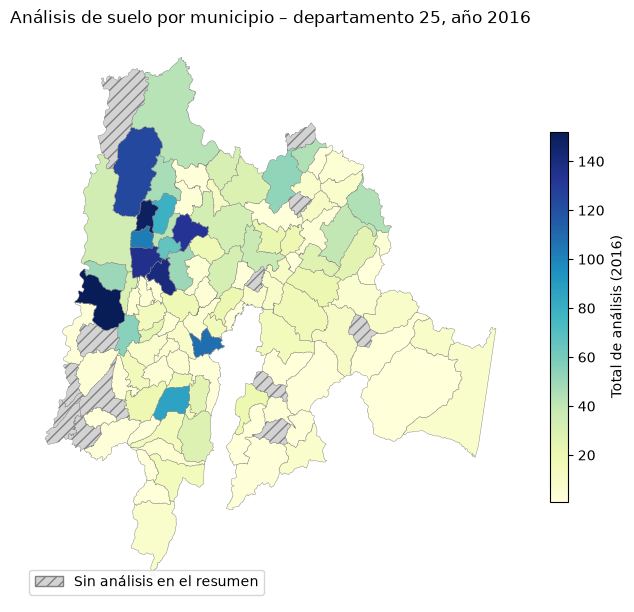

In [14]:
# Desarrollo
# Une el resumen a los polígonos, calcula área en una proyección métrica y genera el mapa.

anio = int(u.loc[u["codigo_municipio"].notna(), "anio"].value_counts().idxmax())     # año con más análisis asociados
base = u[(u["anio"] == anio).fillna(False).astype(bool) & u["codigo_municipio"].notna()]
resumen_anual = (base.groupby("codigo_municipio", as_index=False)
                 .agg(total_analisis=("id_fila", "size"), ph_validos=("ph_valido", "sum"), ph_media_valido=("ph_media_aux", "mean")))
resumen_anual.insert(1, "anio", anio)

municipios_validos["codigo_municipio"] = municipios_validos["mpio_cdpmp"].astype(str).str.strip()
print("Año:", anio, "| claves únicas (polígonos, resumen):", municipios_validos["codigo_municipio"].is_unique, resumen_anual["codigo_municipio"].is_unique)

mapa_municipal = municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)
mapa_municipal["indicador_merge"] = mapa_municipal["_merge"].astype(str)
mapa_municipal = mapa_municipal.drop(columns="_merge")
assert len(mapa_municipal) == len(municipios_validos)
print(type(mapa_municipal).__name__, mapa_municipal.geometry.name, mapa_municipal.crs)

sin_geom = resumen_anual[~resumen_anual["codigo_municipio"].isin(municipios_validos["codigo_municipio"])]
sin_muni = int(((u["anio"] == anio).fillna(False).astype(bool) & u["codigo_municipio"].isna()).sum())
print("Municipios sin resumen:", int(mapa_municipal["total_analisis"].isna().sum()), "| códigos del resumen sin geometría:", sin_geom["codigo_municipio"].tolist())
conciliacion = pd.DataFrame({"concepto": [f"análisis {anio}", "en el mapa", "con municipio sin geometría", "sin municipio"],
                             "n": [len(base) + sin_muni, int(mapa_municipal["total_analisis"].sum()), int(sin_geom["total_analisis"].sum()), sin_muni]})
display(conciliacion)
assert conciliacion["n"][0] == conciliacion["n"][1:].sum()

mapa_municipal["area_ha"] = mapa_municipal.to_crs(epsg=9377).geometry.area / 10000    # metros, no grados

mapa_municipal["cod_dep"] = mapa_municipal["codigo_municipio"].str[:2]
dep = mapa_municipal.groupby("cod_dep")["total_analisis"].sum().idxmax()                # departamento con más análisis
sub = mapa_municipal[mapa_municipal["cod_dep"] == dep]
fig, ax = plt.subplots(figsize=(8, 8))
sub.plot(column="total_analisis", ax=ax, cmap="YlGnBu", edgecolor="grey", linewidth=0.3, legend=True,
         legend_kwds={"label": f"Total de análisis ({anio})", "shrink": 0.6},
         missing_kwds={"color": "lightgrey", "edgecolor": "grey", "hatch": "///", "label": "Sin análisis en el resumen"})
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="lightgrey", ec="grey", hatch="///", label="Sin análisis en el resumen")], loc="lower left")
ax.set_title(f"Análisis de suelo por municipio – departamento {dep}, año {anio}"); ax.set_axis_off()
fig.savefig(OUT + "/mapa_analisis.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretación:**

_Presenta los controles y explica el alcance del resultado._

El merge une atributos por una clave de texto de cinco cifras y no mira la posición de las geometrías

Las hectáreas se calculan en EPSG:9377 (metros) porque en grados el área no es una superficie constante: un grado de longitud mide distinto según la latitud. 

Alcance: no tener registros no demuestra cero análisis en el territorio, la media de pH describe solo las observaciones disponibles

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

Inválidas tras proyectar: 0 0
Piezas: 9 | tipos: {'Polygon': 5, 'MultiPolygon': 4}
Contactos de área cero descartados: 0
Piezas poligonales: 15 | área total (ha): 4545.23
Suma de piezas 4545.2335 ha vs unión 4545.2335 ha -> solape: -0.0000 ha


,id_igac,area_original_ha,area_ha,razon,resultado
0,0,1597.896924,1597.896924,1.0,íntegro dentro de municipios
1,1,359.443210,359.443210,1.0,íntegro dentro de municipios
2,2,1288.865623,1288.865623,1.0,íntegro dentro de municipios
3,3,876.420920,876.420920,1.0,íntegro dentro de municipios
4,4,422.606857,422.606857,1.0,íntegro dentro de municipios


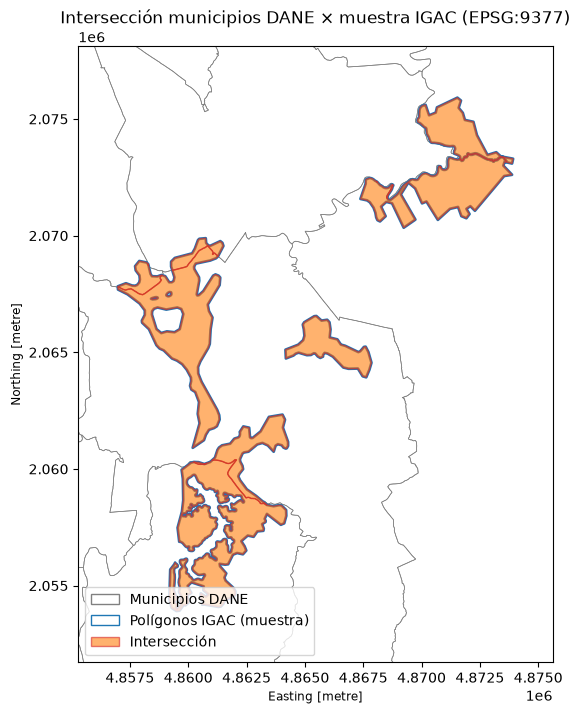

In [15]:
# Desarrollo
# Intersecta con overlay, calcula áreas de piezas y explica los límites de la integración espacial.

gcol = municipios_validos.geometry.name
municipios_m = municipios_validos[["codigo_municipio", gcol]].to_crs(epsg=9377)
capacidad_m = capacidad_valida.to_crs(epsg=9377)
capacidad_m.insert(0, "id_igac", capacidad_m.index.astype(int))                      # fila original del polígono IGAC
attrs = [c for c in capacidad_m.columns if c not in ("id_igac", gcol)]
capacidad_m = capacidad_m.rename(columns={c: "igac_" + c for c in attrs})            # evita nombres duplicados
capacidad_m["area_original_ha"] = capacidad_m.geometry.area / 10000
print("Inválidas tras proyectar:", int((~municipios_m.is_valid).sum()), int((~capacidad_m.is_valid).sum()))

res = gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)
print("Piezas:", len(res), "| tipos:", res.geom_type.value_counts().to_dict())
res = res.explode(index_parts=False)                                                  # una geometría simple por fila
res["area_ha"] = res.geometry.area / 10000                                            # área de la pieza, no del atributo
contactos = ~res.geom_type.isin(POLI) | (res["area_ha"] <= 0)
print("Contactos de área cero descartados:", int(contactos.sum()))
intersecciones = res[~contactos].reset_index(drop=True)
intersecciones.insert(0, "id_pieza", range(len(intersecciones)))
print("Piezas poligonales:", len(intersecciones), "| área total (ha):", round(intersecciones["area_ha"].sum(), 2))

resumen_inter = (intersecciones.groupby("codigo_municipio", as_index=False)
                 .agg(area_intersectada_ha=("area_ha", "sum"), n_piezas=("id_pieza", "size")))
mapa_municipal = mapa_municipal.merge(resumen_inter, on="codigo_municipio", how="left", validate="one_to_one")
mapa_municipal[["area_intersectada_ha", "n_piezas"]] = mapa_municipal[["area_intersectada_ha", "n_piezas"]].fillna(0)

# Riesgo de solapes: si la suma de piezas supera el área de su unión, hay áreas contadas dos veces
union_ha = intersecciones.geometry.union_all().area / 10000
print(f"Suma de piezas {intersecciones['area_ha'].sum():.4f} ha vs unión {union_ha:.4f} ha -> solape: {intersecciones['area_ha'].sum() - union_ha:.4f} ha")

# Contraste por polígono IGAC con tolerancia explícita (0,1 %)
TOL = 0.001
cmp_igac = capacidad_m[["id_igac", "area_original_ha"]].merge(
    intersecciones.groupby("id_igac", as_index=False)["area_ha"].sum(), on="id_igac", how="left", validate="one_to_one").fillna(0)
cmp_igac["razon"] = cmp_igac["area_ha"] / cmp_igac["area_original_ha"]
cmp_igac["resultado"] = np.where((cmp_igac["razon"] - 1).abs() <= TOL, "íntegro dentro de municipios",
                                 np.where(cmp_igac["razon"] < 1, "parte fuera de los municipios", "suma excede el original"))
display(cmp_igac)

xmin, ymin, xmax, ymax = capacidad_m.total_bounds
mx, my = (xmax - xmin) * 0.1, (ymax - ymin) * 0.1
fig, ax = plt.subplots(figsize=(9, 8))
municipios_m.cx[xmin - mx:xmax + mx, ymin - my:ymax + my].plot(ax=ax, facecolor="none", edgecolor="grey", linewidth=0.5)
capacidad_m.plot(ax=ax, facecolor="none", edgecolor="tab:blue", linewidth=2)
intersecciones.plot(ax=ax, facecolor="tab:orange", edgecolor="tab:red", alpha=0.6)
ax.set_xlim(xmin - mx, xmax + mx); ax.set_ylim(ymin - my, ymax + my)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="none", ec="grey", label="Municipios DANE"),
                   plt.Rectangle((0, 0), 1, 1, fc="none", ec="tab:blue", label="Polígonos IGAC (muestra)"),
                   plt.Rectangle((0, 0), 1, 1, fc="tab:orange", ec="tab:red", alpha=0.6, label="Intersección")], loc="lower left")
ax.set_title("Intersección municipios DANE × muestra IGAC (EPSG:9377)")
fig.savefig(OUT + "/mapa_interseccion.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretación:**

_Presenta los controles y explica el alcance del resultado._

El merge une atributos por una clave (el código municipal) sin mirar geometrías, el overlay usa posición y forma y devuelve las piezas donde se superponen municipios y polígonos IGAC, sin necesitar clave común. 

Límites: area_intersectada_ha es una suma de áreas y solo equivale a cobertura única si no hay solapes (se diagnostica arriba), son cinco polígonos, que no permiten estimar la capacidad de uso de un municipio ni asignar una clase IGAC a una muestra de AGROSAVIA.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [ ]:
# Desarrollo
# Publica, vuelve a leer y valida el resultado con pd.testing.assert_frame_equal.

analisis_integrados = u.drop(columns="ph_media_aux").assign(fuente_territorial="divipola.csv", corte_divipola="2024")
analisis_integrados.to_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow", compression="snappy", index=False)
leido = pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")
a = analisis_integrados.sort_values("id_fila").reset_index(drop=True)
b = leido.sort_values("id_fila").reset_index(drop=True)
for d in (a, b):                                    # Parquet devuelve None donde pandas tenía NaN: se igualan los nulos
    for c in d.columns[d.dtypes == object]:
        d[c] = d[c].where(d[c].notna(), np.nan)
pd.testing.assert_frame_equal(a, b)
print("Parquet:", a.shape, "-> relectura idéntica (contenido, orden por id_fila y tipos)")

pendientes = a.loc[~a["estado_union"].isin(["coincide", "equivalencia_documentada"]),
                   ["id_fila", C_DEP_S, C_MUN_S, "dep_key", "mun_key", "estado_union_inicial", "estado_union"]]
controles = pd.DataFrame([("filas agrosavia", n_suelo0), ("filas divipola", n_terr0), ("cobertura antes (n)", cob_antes[0]),
    ("cobertura antes (%)", cob_antes[1]), ("cobertura después (n)", cob_despues[0]), ("cobertura después (%)", cob_despues[1]),
    ("municipios en dimensión", len(dim)), ("claves ambiguas", len(ambiguas)), ("polígonos aptos DANE", len(municipios_validos)),
    ("piezas de intersección", len(intersecciones)), ("pendientes", len(pendientes))], columns=["control", "valor"])
for nombre, df in [("controles", controles), ("equivalencias", equivalencias), ("resumen_municipal", resumen_municipal),
                   ("pendientes", pendientes), ("conciliacion_mapa", conciliacion)]:
    df.to_csv(f"{OUT}/{nombre}.csv", index=False, encoding="utf-8-sig")

# GeoPackage nuevo en cada ejecución (sin append); el indicador del merge pasa a texto
GPKG = OUT + "/resultados_espaciales.gpkg"
if os.path.exists(GPKG):
    os.remove(GPKG)
for g in (mapa_municipal, intersecciones):
    for c in g.columns:
        if str(g[c].dtype) in ("category", "str", "string"):
            g[c] = g[c].astype(object)
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)

for capa, orig, clave in [("municipios", mapa_municipal, "codigo_municipio"), ("intersecciones", intersecciones, "id_pieza")]:
    rel = gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer=capa, engine="pyogrio")
    o, r = orig.sort_values(clave).reset_index(drop=True), rel.sort_values(clave).reset_index(drop=True)
    num = [c for c in o.columns if c != o.geometry.name and pd.api.types.is_numeric_dtype(o[c])]
    assert len(o) == len(r) and (o[clave].astype(str) == r[clave].astype(str)).all() and o.crs == r.crs
    assert all(np.allclose(o[c].astype(float), r[c].astype(float), equal_nan=True) for c in num)
    a_o, a_r = o.to_crs(epsg=9377).geometry.area, r.to_crs(epsg=9377).geometry.area
    assert np.allclose(a_o, a_r, rtol=1e-9), "las áreas cambiaron"                  # áreas con tolerancia
    assert o.geometry.geom_equals(r.geometry).all(), "las formas cambiaron"         # igualdad topológica (ignora Polygon vs MultiPolygon)
    dif = {c: (str(o[c].dtype), str(r[c].dtype)) for c in o.columns if c in r.columns and str(o[c].dtype) != str(r[c].dtype)}
    print(f"{capa}: {len(r)} filas | CRS {r.crs.to_epsg()} | geometría '{r.geometry.name}' | tipos geométricos: "
          f"{o.geom_type.value_counts().to_dict()} -> {r.geom_type.value_counts().to_dict()} | tipos de columna distintos: {dif or 'ninguno'}")
print(sorted(os.listdir(OUT)))

Parquet: (92738, 50) -> relectura idéntica (contenido, orden por id_fila y tipos)


**Interpretación:**

_Presenta los controles obtenidos y explica sus límites._

Parquet conserva todas las filas con los tipos del contrato y no repite la geometría municipal, se relee y se compara ordenado por id_fila con assert_frame_equal. 

El GeoPackage tiene dos capas separadas, se recrea en cada ejecución y se relee verificando filas, claves, CRS, geometría activa, valores y áreas con tolerancia

Límite: que la relectura coincida prueba una publicación fiel, no que el enlace territorial sea correcto.

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
